# Clustering assumptions: worked examples

`ClusteringAssumptionsChecker` asks: *given the characteristics of this dataset, is this clustering algorithm a sensible choice?*

There is no target, so the checker estimates cluster structure from the data itself. The examples use synthetic datasets whose geometry is known by construction, so you can see the checker reach the right conclusion for the right reason.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets

from assumptions import ClusteringAssumptionsChecker

warnings.filterwarnings("ignore")
rng = np.random.default_rng(0)

def frame(X):
    return pd.DataFrame(X, columns=[f"x{i}" for i in range(X.shape[1])])

blobs_core = datasets.make_blobs(450, centers=3, random_state=1)[0]
examples = {
    "Blobs": datasets.make_blobs(500, centers=3, random_state=1)[0],
    "Elongated blobs": datasets.make_blobs(500, centers=3, random_state=170)[0] @ [[0.6, -0.6], [-0.4, 0.8]],
    "Unequal variance": datasets.make_blobs(500, cluster_std=[1.0, 2.5, 0.5], random_state=170)[0],
    "Moons": datasets.make_moons(500, noise=0.05, random_state=0)[0],
    "Circles": datasets.make_circles(500, factor=0.5, noise=0.05, random_state=0)[0],
    "Blobs + 10% noise": np.vstack([blobs_core, rng.uniform(blobs_core.min(0) - 3, blobs_core.max(0) + 3, size=(50, 2))]),
    "Uniform (no clusters)": rng.uniform(size=(500, 2)),
}

## The datasets

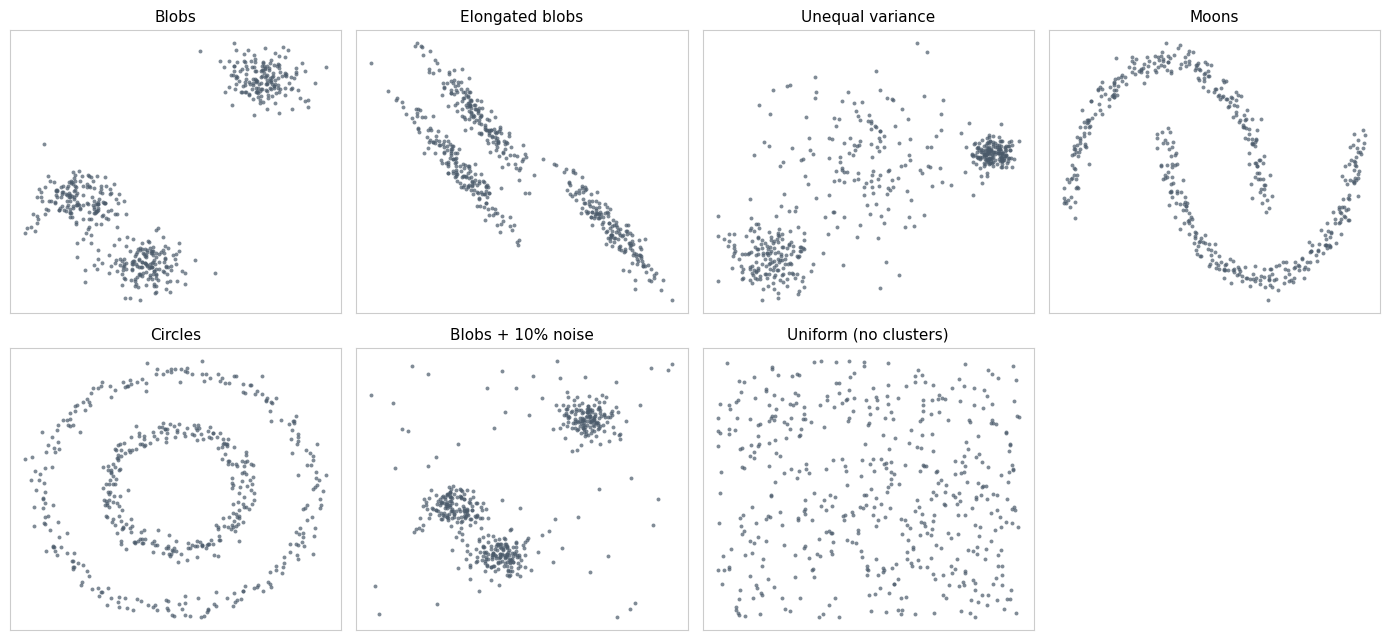

In [2]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for ax, (name, X) in zip(axes.flat, examples.items()):
    ax.scatter(X[:, 0], X[:, 1], s=8, color="#4a5a6a", alpha=0.7, linewidths=0)
    ax.set_title(name, fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_color("#cccccc")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

## Ranking every algorithm on every dataset

Leave out `algorithm` to run all checks and rank the supported algorithms. The table shows each algorithm's suitability and the shape the checker inferred.

In [3]:
import contextlib, io

rows, checkers = [], {}
for name, X in examples.items():
    checker = ClusteringAssumptionsChecker(frame(X))
    with contextlib.redirect_stdout(io.StringIO()):  # hide the "no algorithm" note
        results = checker.check_assumptions()
    checkers[name] = checker
    row = {"dataset": name, "shape": results["cluster_shape"]["shape"] or "inconclusive"}
    row.update({r["algorithm"]: r["suitability"] for r in checker.report["recommendations"]})
    rows.append(row)

order = ["dataset", "shape", "KMeans", "MiniBatchKMeans", "AgglomerativeClustering", "DBSCAN",
         "OPTICS", "GaussianMixture", "SpectralClustering"]
pd.DataFrame(rows)[order].set_index("dataset")

,shape,KMeans,MiniBatchKMeans,AgglomerativeClustering,DBSCAN,OPTICS,GaussianMixture,SpectralClustering
dataset,,,,,,,,
Blobs,globular,high,medium,high,high,high,high,high
Elongated blobs,ellipsoidal,unsuitable,unsuitable,medium,high,high,high,high
Unequal variance,globular,medium,low,low,medium,high,high,medium
Moons,non_convex,unsuitable,unsuitable,medium,high,high,unsuitable,high
Circles,non_convex,unsuitable,unsuitable,medium,high,high,unsuitable,high
Blobs + 10% noise,globular,medium,low,medium,high,high,medium,medium
Uniform (no clusters),inconclusive,low,low,low,low,low,low,low


Reading the table:

- **Blobs**: K-Means reproduces the separated dense regions, so it is a sensible, fast choice.
- **Elongated blobs**: a Gaussian mixture reproduces the clusters but K-Means cuts across them.
- **Unequal variance**: GMM and OPTICS cope; K-Means misplaces boundaries and DBSCAN's single `eps` can't fit both densities.
- **Moons and circles**: non-convex, so K-Means and GMM are unsuitable, while DBSCAN, OPTICS and spectral clustering recover them.
- **Background noise**: density-based methods label outliers as noise; the others must assign them to a cluster.
- **Uniform data**: the Hopkins statistic finds no cluster tendency, so every algorithm is capped at *low*.

## Why: the reasons behind one ranking

In [4]:
for rec in checkers["Moons"].report["recommendations"]:
    print(f"{rec['algorithm']:24s} {rec['suitability']:11s} {rec['reason']}")

DBSCAN                   high        Density-based: finds arbitrarily shaped clusters and labels noise.
OPTICS                   high        Density-based like DBSCAN, but copes with clusters of different densities.
SpectralClustering       high        Graph-based: recovers connected but non-convex clusters.
AgglomerativeClustering  medium      Clusters are non-convex: use linkage='single' (ward, average and complete favour compact clusters), though single linkage chains through noise.
KMeans                   unsuitable  Clusters are non-convex; K-Means only draws convex, roughly spherical clusters and cuts across them.
MiniBatchKMeans          unsuitable  Clusters are non-convex; K-Means only draws convex, roughly spherical clusters and cuts across them.
GaussianMixture          unsuitable  Clusters are non-convex; each Gaussian is an ellipsoid, so one cluster is split across several components.


## Checking one algorithm

Pass `algorithm=` (aliases such as `"GMM"`, `"Hierarchical"` and `"Spectral"` work) for a status, a reason and specific advice, plus the full diagnostic report.

In [5]:
checker = ClusteringAssumptionsChecker(frame(examples["Moons"]), algorithm="KMeans")
checker.check_assumptions()
checker.report_assumptions()


🔍 Assumption Diagnostics Report

🧠 Feature Types
------------------------------
mixed_types: False
numeric_features: ['x0', 'x1']
non_numeric_features: []
notes: All 2 features are numeric.

🧠 Sample Size
------------------------------
n_samples: 500
n_features: 2
large_n: False
very_large_n: False
notes: 500 rows and 2 numeric features: every algorithm is computationally feasible.

🧠 Scaling Issues
------------------------------
scaling_needed: False
std_ratio: 1.75
range_ratio: 1.78
max_std_feature: x0
min_std_feature: x1
threshold: 10.0
notes: Feature 'x0' has a standard deviation 1.8× larger than 'x1'. Feature scales are reasonably aligned — scaling optional.

🧠 Duplicates
------------------------------
has_duplicates: False
duplicate_frac: 0.0
notes: 0.0% duplicate rows.

🧠 Outliers
------------------------------
has_noise: False
outlier_frac: 0.0
notes: No meaningful outliers detected.

🧠 Dimensionality
------------------------------
distances_concentrated: False
n_features: 2
d

In [6]:
checker = ClusteringAssumptionsChecker(frame(examples["Elongated blobs"]), algorithm="GMM")
results = checker.check_assumptions()
print(results["status"], "-", results["reason"])
for note in results["advice"]:
    print(" -", note)

suitable - Models clusters as ellipsoids of any orientation and size, with soft membership.
 - Full-covariance components fit the elongated clusters found in the data
 - Needs n_components (the data suggests about 3)
 - Gives probabilistic (soft) membership via predict_proba


## Real-world complications

Scale disparity, categorical columns and missing values are reported alongside the geometry.

In [7]:
df = frame(examples["Blobs"])
df["x1"] *= 1000                                      # very different scales
df["region"] = np.where(df["x0"] > 0, "north", "south")  # a categorical column
df.loc[:24, "x0"] = np.nan                            # some missing values

checker = ClusteringAssumptionsChecker(df)
with contextlib.redirect_stdout(io.StringIO()):
    checker.check_assumptions()
for caveat in checker.report["caveats"]:
    print("•", caveat)
kmeans = next(r for r in checker.report["recommendations"] if r["algorithm"] == "KMeans")
print()
print("KMeans:", kmeans["suitability"])
for note in kmeans["notes"]:
    print(" -", note)

• 1 non-numeric column(s) ['region'] were excluded from the geometric checks, which use the 2 numeric column(s).
• Standardise features before clustering: every algorithm here is distance- or variance-based.
• Validate the result: no single score proves clusters are real, so compare silhouette scores, stability across seeds or subsamples, and domain sense.

KMeans: medium
 - Non-numeric columns present: needs numeric input. Consider K-Prototypes for mixed data
 - K-Means reproduces the separated dense regions in the data
 - Standardise features first: their scales differ by 1454.73× and distances would be dominated by the largest
 - Does not accept missing values; impute or drop incomplete rows
 - Needs n_clusters (the data suggests about 3)
